# Red Sea: 18 years of satellite observations with BigQuery

Sea surface temperature (SST) and sea surface height (SSH) analysis of the Red Sea (1998–2015) on Google Cloud: SQL queries with BigQuery, trend and seasonal regression, K-means and PCA. See the README for the summary of results.

**Before starting:**

You need to install Basemap. Do it only once.

In [ ]:
!pip install basemap basemap-data-hires --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.0/56.0 kB 833.1 kB/s eta 0:00:00
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    status = run_func(*args)
             ^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/req_command.py", line 67, in wrapper
    return func(self, options, args)
           ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/commands/install.py", line 377, in run
    requirement_set = resolver.resolve(
                      ^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/resolution/resolvelib/resolver.py", line 179, in resolve
    self.factory.preparer.prepare_linked_requirements_more(reqs)
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/operations/prepare.py", line 554, in prepare_linked_requirements_more
    self._complete_partial_requirem

**Goal of this practice:**

In this second practice, we will use the "BigQuery" technology which uses a network of computers at Google. We still use the Google Colab to run this Jupyter notebook and interact with the Google Cloud Platform. We will work directly on the whole database (1998-2015, 150Go) and you will perform basic statistics. The idea is to show that BigQuery is able to manage very large datasets efficiently (few seconds). We will manipulate the SST/SSH dataset with BigQuery using the magic command *%%bigquery*.

**Import libraries:**

- matplotlib (2D plotting)
- pylab (scientific computing)
- basemap (plotting 2D data on maps)
- scikit-learn (machine learning)
- pandas (data structures and data analysis tools)

In [ ]:
%matplotlib inline
%pylab inline
from mpl_toolkits.basemap import Basemap
import sklearn
import pandas as pd
from scipy.stats.mstats import zscore
import warnings
warnings.filterwarnings("ignore") # disable warnings
pylab.rcParams['figure.figsize']=(8,8) # graph size

Populating the interactive namespace from numpy and matplotlib


**Declare functions:**
- plot_im (plot satellite image with geographic coordinates)
- plot_ts (plot time series)

In [ ]:
# function to plot images
def plot_im(lon,lat,im,size_points,var_name):

    # transform to arrays (just in case)
    lon=array(lon)
    lat=array(lat)
    im=array(im)

    if max(lon)-min(lon)<100:
      # Mercator projection (for small zone)
      m=Basemap(projection='merc',llcrnrlat=nanmin(lat),urcrnrlat=nanmax(lat),\
                llcrnrlon=nanmin(lon),urcrnrlon=nanmax(lon),lat_0=(nanmax(lat)+nanmin(lat))*0.5,\
                lon_0=(nanmax(lon)+nanmin(lon))*0.5,resolution='l')
    else:
      # Orthogonal projection (for large zone)
      m=Basemap(projection='robin',lat_0=0,lon_0=0,resolution='l')
    # you can use other projections (see https://matplotlib.org/basemap/users/mapsetup.html)

    # transform (lon,lat) to (x,y)
    x,y=m(lon,lat)

    # plot
    #im=ma.masked_where(isnan(im),im)
    res=m.scatter(x,y,size_points,im,'o',alpha=1,cmap='jet',lw=0)
    m.drawcoastlines()
    m.fillcontinents()
    parallels = linspace(nanmin(lat),nanmax(lat),15)
    meridians = linspace(nanmin(lon),nanmax(lon),15)
    #m.drawparallels(parallels,labels=[1,0,0,1],fontsize=10)
    #m.drawmeridians(meridians,labels=[1,0,0,1],fontsize=10)
    cb=m.colorbar(res,location="right")
    cb.set_label(var_name,fontsize=15)

#  function to plot images but only used with our correlation plot to have it between -1 and 1
def plot_im1(lon,lat,im,size_points,var_name):

    # transform to arrays (just in case)
    lon=array(lon)
    lat=array(lat)
    im=array(im)

    if max(lon)-min(lon)<100:
      # Mercator projection (for small zone)
      m=Basemap(projection='merc',llcrnrlat=nanmin(lat),urcrnrlat=nanmax(lat),\
                llcrnrlon=nanmin(lon),urcrnrlon=nanmax(lon),lat_0=(nanmax(lat)+nanmin(lat))*0.5,\
                lon_0=(nanmax(lon)+nanmin(lon))*0.5,resolution='l')
    else:
      # Orthogonal projection (for large zone)
      m=Basemap(projection='robin',lat_0=0,lon_0=0,resolution='l')
    # you can use other projections (see https://matplotlib.org/basemap/users/mapsetup.html)

    # transform (lon,lat) to (x,y)
    x,y=m(lon,lat)

    # plot
    #im=ma.masked_where(isnan(im),im)
    res=m.scatter(x,y,size_points,im,'o',alpha=1,cmap='jet',lw=0,vmin=-1,vmax=1)
    m.drawcoastlines()
    m.fillcontinents()
    parallels = linspace(nanmin(lat),nanmax(lat),15)
    meridians = linspace(nanmin(lon),nanmax(lon),15)
    #m.drawparallels(parallels,labels=[1,0,0,1],fontsize=10)
    #m.drawmeridians(meridians,labels=[1,0,0,1],fontsize=10)
    cb=m.colorbar(res,location="right")
    cb.set_label(var_name,fontsize=15)


# function to plot time series
def plot_ts(time,ts,line_type,var_name):

    # plot
    plot_date(time-719177.25,ts,line_type)
    xlabel('Time',fontsize=15)
    ylabel(var_name,fontsize=15)

**Connection to the GCP:**

Authentication to the Google Cloud Platform (the BigQuery dataset was provided as part of the IMT Atlantique course).

In [ ]:
import os
os.environ['USE_AUTH_EPHEM'] = '0'

from google.colab import auth
auth.authenticate_user()

The Google Cloud Platform has set up a tool to handle large databases. This is called "BigQuery" and it is based on the NoSQL ("Not only SQL") language. The syntaxe in BigQuery is very similar to the pandas example given in the first practice. SQL language is suitable to manipulate and compute basic statistics such as the mean, standard deviation, minimum, maximum, correlation, etc... Here you will find the list of basic functions: https://cloud.google.com/bigquery/docs/reference/legacy-sql?hl=fr.

In the example below, we plot the mean SST map in the Mediterranean Sea over the period 1998-2015. The full 18-years dataset is stored in the BigQuery table *bdo2020.bdo2020.1998_2015*. The project is called *YOUR_GCP_PROJECT* (strange but you have to provide it). The result of the BigQuery request is stored in the *output* dataframe.

**1.SST / SST Analysis**

In [ ]:
%%bigquery data --project YOUR_GCP_PROJECT
SELECT time, month, AVG(sst) AS sst_mean, AVG(ssh) AS ssh_mean
FROM bdo2020.bdo2020.1998_2015_withtimes
WHERE lon>32 AND lon<44 AND lat>12 AND lat<30
GROUP BY time, month
ORDER BY time, month

Query is running:   0%|          |

Downloading:   0%|          |

<Axes: title={'center': 'ssh_mean'}, xlabel='month'>

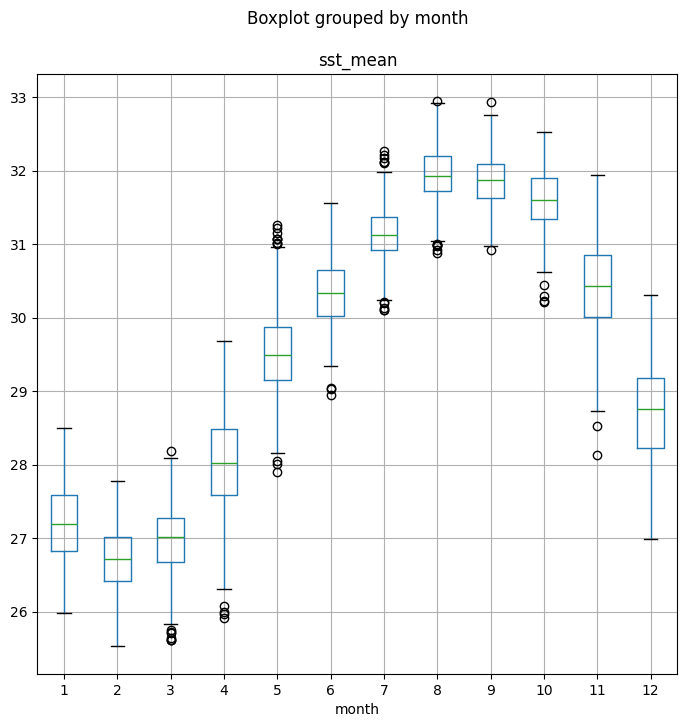

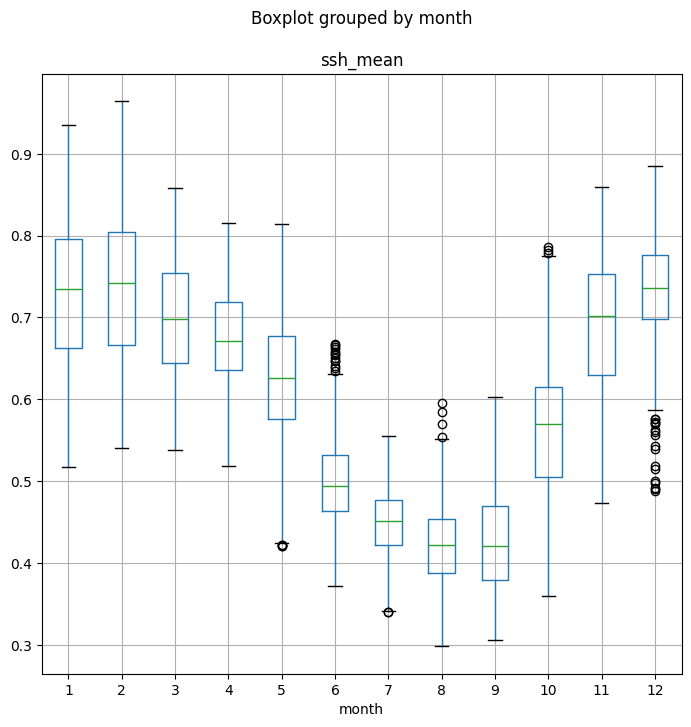

In [ ]:
# plot results
data.boxplot(column='sst_mean', by='month')
data.boxplot(column='ssh_mean', by='month')

In order to better see this correlation , we will add a spatial plot for it.

In [ ]:
%%bigquery output7 --project YOUR_GCP_PROJECT
SELECT lon,lat , CORR(sst,ssh) as corr_ssh_sst
FROM bdo2020.bdo2020.1998_2015_withtimes
WHERE lon<44 AND lon>32 AND lat<30 AND lat>12
GROUP BY lon,lat


Query is running:   0%|          |

Downloading:   0%|          |

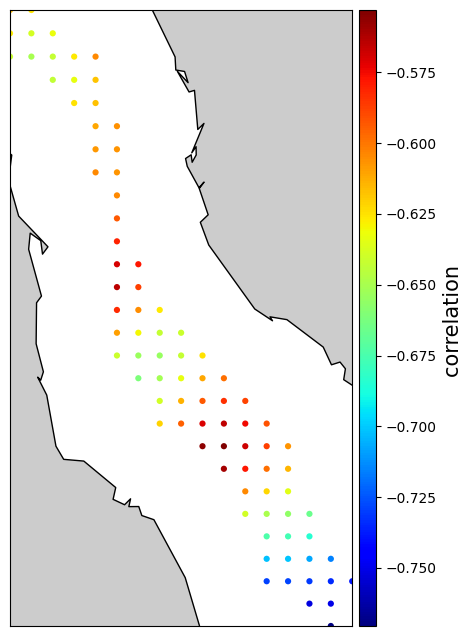

In [ ]:
plot_im1(output7.lon ,output7.lat,output7.corr_ssh_sst,20, 'correlation ')

**2.Trend Extraction**

In [ ]:
%%bigquery df_sst_rs --project YOUR_GCP_PROJECT
SELECT
time, AVG(sst) AS sst_mean_space ,AVG (ssh) ssh_mean_space
FROM
  bdo2020.bdo2020.1998_2015
WHERE
  lon >= 32 AND lon <= 44
  AND lat >= 12 AND lat <= 30
GROUP BY
  time
ORDER BY
  time

Query is running:   0%|          |

Downloading:   0%|          |

In [ ]:
# convertir le temps en années
time_years = (df_sst_rs.time - df_sst_rs.time.iloc[0]) / 365.25

sst = df_sst_rs.sst_mean_space.values

slope_sst, intercept_sst, r, p, stderr = stats.linregress(time_years, sst)

print("Tendance SST =", slope_sst, "°C / an")
print("p-value =", p)
ssh = df_sst_rs.ssh_mean_space.values

slope_ssh, intercept_ssh, r, p, stderr = stats.linregress(time_years, ssh)
print(intercept_sst)
print(intercept_ssh)
print("Tendance SSH =", slope_ssh, "m / an")
print("p-value =", p)



Tendance SST = 0.015070504537687025 °C / an
p-value = 0.0010665781380896923
29.420108824633026
0.5584400734029416
Tendance SSH = 0.005131859826501146 m / an
p-value = 6.478428344865197e-55


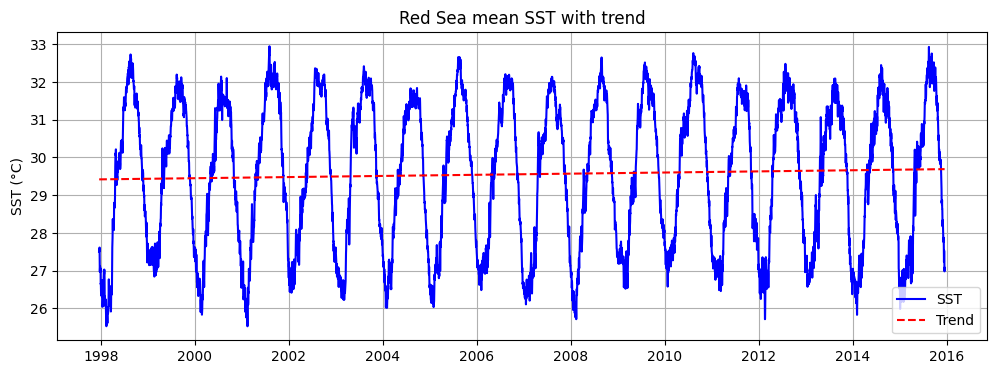

In [ ]:
sst_trend = intercept_sst + slope_sst * time_years

figure(figsize=(12,4))
plot_date(df_sst_rs.time - 719177.25, sst, '-b', label='SST')
plot_date(df_sst_rs.time - 719177.25, sst_trend, '--r', label='Trend')
ylabel('SST (°C)')
title('Red Sea mean SST with trend')
legend()
grid()

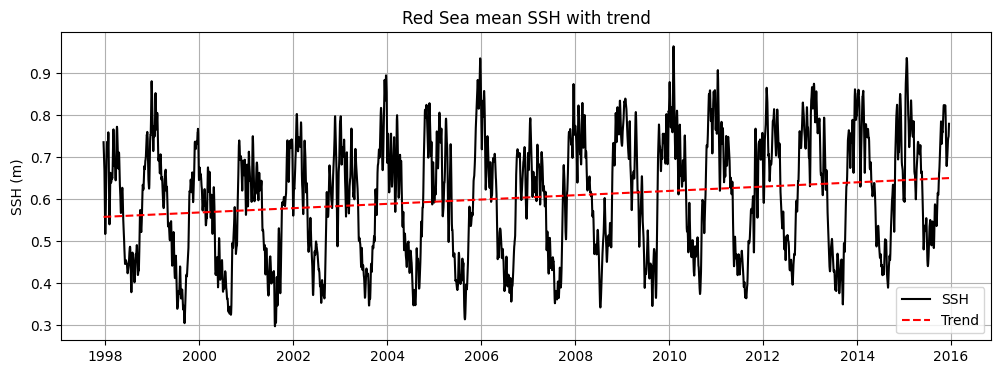

In [ ]:
ssh_trend = intercept_ssh + slope_ssh * time_years

figure(figsize=(12,4))
plot_date(df_sst_rs.time - 719177.25, ssh, '-k', label='SSH')
plot_date(df_sst_rs.time - 719177.25, ssh_trend, '--r', label='Trend')
ylabel('SSH (m)')
title('Red Sea mean SSH with trend')
legend()
grid()


In [ ]:
%%bigquery projet3 --project YOUR_GCP_PROJECT
SELECT time, AVG(sst) AS mean_sst, AVG(ssh) AS mean_ssh
FROM bdo2020.bdo2020.1998_2015
WHERE lon>33 AND lon<42 AND lat>14 AND lat<29
GROUP BY time
ORDER BY time

Query is running:   0%|          |

Downloading:   0%|          |

In [ ]:
import numpy as np
from scipy import stats

def prediction_interval(y_true, y_pred, X, alpha=0.05):
    """
    Calcul d'un intervalle de confiance pour la régression linéaire
    y_true : valeurs observées
    y_pred : valeurs prédites par le modèle
    X : matrice des variables explicatives (avec biais si intercept)
    alpha : niveau de confiance (0.05 → 95 %)
    """
    n = len(y_true)      # nombre d'observations
    p = X.shape[1]       # nombre de paramètres
    dof = n - p          # degrés de liberté

    # Erreur résiduelle
    residuals = y_true - y_pred
    s_err = np.sqrt(np.sum(residuals**2) / dof)

    # Pour chaque prédiction
    mean_X = np.mean(X, axis=0)
    confs = []
    for x in X:
        se = s_err * np.sqrt(1 + (1/n) + ((x - mean_X) @ (x - mean_X).T) / np.sum((X - mean_X)**2))
        confs.append(se)

    confs = np.array(confs)

    t_val = stats.t.ppf(1 - alpha/2, dof)
    interval = t_val * confs
    return interval


This time try using a multiple linear regression to model the evolution: $mean_sst = (a\times time) + (b\times sin(\omega t) + c \times cos(\omega \times t) +d$

=== Modèle tendance + saisonnier ===
a (tendance) = 6.4200e-06
b (cos) = -1.5332e+00
c (sin) = -2.1583e+00
Intercept d = 29.556
Tendance SST sur 10 ans : 0.023 °C

=== Modèle linéaire seul ===
a_lin = 4.1261e-05
Intercept d_lin = 29.556
Tendance SST sur 10 ans : 0.151 °C
Différence des intercepts : 0.000


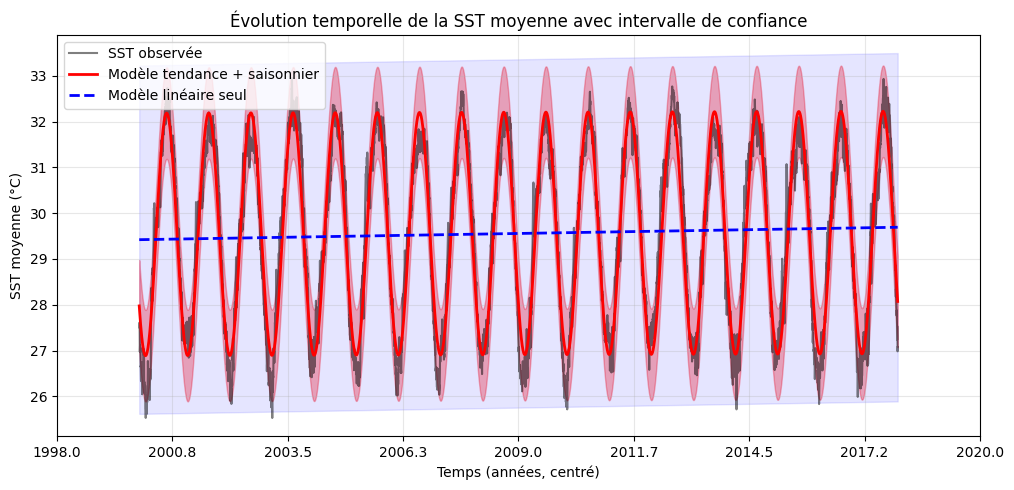

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Données
time = projet3.time.values          # temps (jours)
mean_sst = projet3.mean_sst.values  # SST moyenne
mean_ssh = projet3.mean_ssh.values  # SSH moyenne

# Centrage du temps (important pour l'interprétation de l'intercept)
t = time - np.mean(time)

# Composantes saisonnières
cos_t = np.cos(2 * np.pi * t / 365.25)
sin_t = np.sin(2 * np.pi * t / 365.25)

# Matrices de régression
X_full = np.vstack((t, cos_t, sin_t)).T   # modèle tendance + saisonnier
X_trend = t.reshape(-1, 1)                # modèle linéaire seul

# Variable étudiée
y = mean_sst

# Modèle avec tendance + cycle saisonnier
model_seasonal = LinearRegression()
model_seasonal.fit(X_full, y)
y_seasonal_pred = model_seasonal.predict(X_full)

interval_seasonal = prediction_interval(y, y_seasonal_pred, X_full)

upper_seasonal = y_seasonal_pred + interval_seasonal
lower_seasonal = y_seasonal_pred - interval_seasonal


# Modèle linéaire seul
model_linear = LinearRegression()
model_linear.fit(X_trend, y)
y_linear_pred = model_linear.predict(X_trend)

interval_linear = prediction_interval(y, y_linear_pred, X_trend)

upper_linear = y_linear_pred + interval_linear
lower_linear = y_linear_pred - interval_linear


# Coefficients du modèle saisonnier
a, b, c = model_seasonal.coef_
d = model_seasonal.intercept_

# Coefficients du modèle linéaire
a_lin = model_linear.coef_[0]
d_lin = model_linear.intercept_

# Tendances sur 10 ans
trend_seasonal_10y = a * 365.25 * 10
trend_linear_10y = a_lin * 365.25 * 10

print("=== Modèle tendance + saisonnier ===")
print(f"a (tendance) = {a:.4e}")
print(f"b (cos) = {b:.4e}")
print(f"c (sin) = {c:.4e}")
print(f"Intercept d = {d:.3f}")
print(f"Tendance SST sur 10 ans : {trend_seasonal_10y:.3f} °C\n")

print("=== Modèle linéaire seul ===")
print(f"a_lin = {a_lin:.4e}")
print(f"Intercept d_lin = {d_lin:.3f}")
print(f"Tendance SST sur 10 ans : {trend_linear_10y:.3f} °C")
print(f"Différence des intercepts : {d_lin - d:.3f}")

plt.figure(figsize=(10, 5))

plt.plot(t, y, color='black', alpha=0.5, label='SST observée')
plt.plot(t, y_seasonal_pred, color='red', linewidth=2,
         label='Modèle tendance + saisonnier')
plt.fill_between(t, lower_seasonal, upper_seasonal, color='red', alpha=0.3)
plt.plot(t, y_linear_pred, color='blue', linestyle='--', linewidth=2,
         label='Modèle linéaire seul')
plt.fill_between(t, lower_linear, upper_linear, color='blue', alpha=0.1)

plt.xlabel("Temps (jours centrés)")
plt.ylabel("SST moyenne (°C)")
plt.title("Évolution temporelle de la SST moyenne avec intervalle de confiance")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
ax = plt.gca()

# Ticks actuels en jours
ticks_days = ax.get_xticks()

# Conversion jours → années
ticks_years = ticks_days / 365.25 +11+1998

# Application
model_ssh_linear.fit(X_trend, y_ssh)
ax.set_xticks(ticks_days)
ax.set_xticklabels([f"{y:.1f}" for y in ticks_years])

plt.xlabel("Temps (années, centré)")
plt.show()


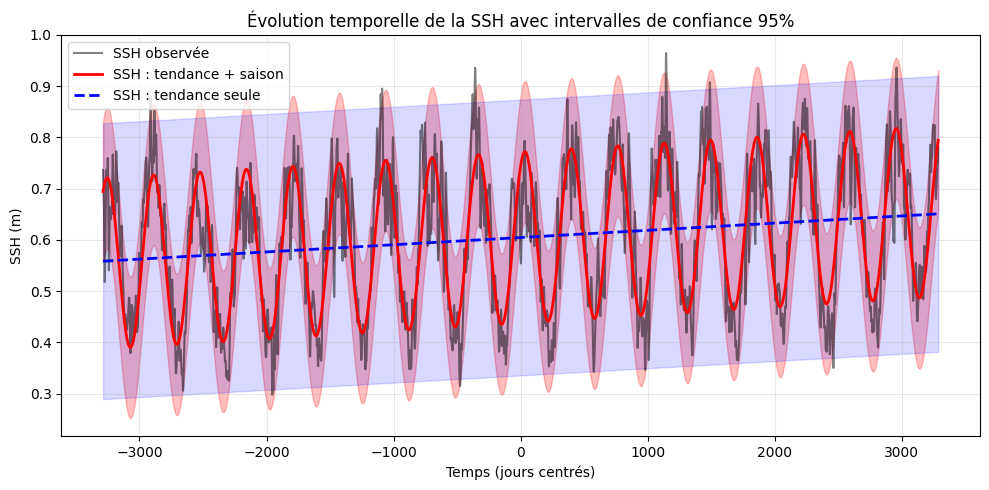


================ SSH =================
Modèle tendance + saisonnier
  a (tendance)  : 1.552e-05 m/jour
  → tendance    : 0.057 m/décennie
  b (cos)       : 1.398e-01 m
  c (sin)       : 9.112e-02 m
  intercept d   : 0.605 m

Modèle linéaire seul
  a_lin         : 1.405e-05 m/jour
  → tendance    : 0.051 m/décennie
  intercept d   : 0.605 m

Différence des tendances (linéaire - saisonnier) : -0.005 m/décennie


In [ ]:
# ==============================
# SSH : modèle affine + saisonnier
# ==============================
y_ssh = mean_ssh

model_ssh_seasonal = LinearRegression()
model_ssh_seasonal.fit(X_full, y_ssh)
y_ssh_seasonal_pred = model_ssh_seasonal.predict(X_full)

# ==============================
# SSH : modèle affine seul
# ==============================
model_ssh_linear = LinearRegression()
model_ssh_linear.fit(X_trend, y_ssh)
y_ssh_linear_pred = model_ssh_linear.predict(X_trend)


interval_ssh_seasonal = prediction_interval(
    y_ssh, y_ssh_seasonal_pred, X_full
)

interval_ssh_linear = prediction_interval(
    y_ssh, y_ssh_linear_pred, X_trend
)

upper_ssh_seasonal = y_ssh_seasonal_pred + interval_ssh_seasonal
lower_ssh_seasonal = y_ssh_seasonal_pred - interval_ssh_seasonal

upper_ssh_linear = y_ssh_linear_pred + interval_ssh_linear
lower_ssh_linear = y_ssh_linear_pred - interval_ssh_linear



plt.figure(figsize=(10,5))

plt.plot(t, y_ssh, color='black', alpha=0.5, label='SSH observée')

plt.plot(t, y_ssh_seasonal_pred, color='red', linewidth=2,
         label='SSH : tendance + saison')
plt.fill_between(t, lower_ssh_seasonal, upper_ssh_seasonal,
                 color='red', alpha=0.25)

plt.plot(t, y_ssh_linear_pred, color='blue', linestyle='--', linewidth=2,
         label='SSH : tendance seule')
plt.fill_between(t, lower_ssh_linear, upper_ssh_linear,
                 color='blue', alpha=0.15)

plt.xlabel("Temps (jours centrés)")
plt.ylabel("SSH (m)")
plt.title("Évolution temporelle de la SSH avec intervalles de confiance 95%")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==============================
# Extraction des coefficients SSH
# ==============================

# --- Modèle affine + saisonnier ---
a_ssh, b_ssh, c_ssh = model_ssh_seasonal.coef_
d_ssh = model_ssh_seasonal.intercept_

# Conversion en m / décennie
trend_ssh_seasonal_decade = a_ssh * 365.25 * 10

# --- Modèle affine seul ---
a_ssh_lin = model_ssh_linear.coef_[0]
d_ssh_lin = model_ssh_linear.intercept_

trend_ssh_linear_decade = a_ssh_lin * 365.25 * 10


# ==============================
# Affichage formaté (rapport / soutenance)
# ==============================

print("\n================ SSH =================")
print("Modèle tendance + saisonnier")
print(f"  a (tendance)  : {a_ssh:.3e} m/jour")
print(f"  → tendance    : {trend_ssh_seasonal_decade:.3f} m/décennie")
print(f"  b (cos)       : {b_ssh:.3e} m")
print(f"  c (sin)       : {c_ssh:.3e} m")
print(f"  intercept d   : {d_ssh:.3f} m")

print("\nModèle linéaire seul")
print(f"  a_lin         : {a_ssh_lin:.3e} m/jour")
print(f"  → tendance    : {trend_ssh_linear_decade:.3f} m/décennie")
print(f"  intercept d   : {d_ssh_lin:.3f} m")

print("\nDifférence des tendances (linéaire - saisonnier) : "
      f"{trend_ssh_linear_decade - trend_ssh_seasonal_decade:.3f} m/décennie")





STATISTIQUES D'EXTRAPOLATION
Période observée : 1998 à ~2016
Période d'extrapolation : ~2016 à 2050

--- SST (Sea Surface Temperature) ---
  Valeur observée (dernière)  : 27.076 °C
  Tendance linéaire           : 0.0151 °C/an
  SST prévue en 2050          : 30.204 °C
  Augmentation prévue         : +3.128 °C

--- SSH (Sea Surface Height) ---
  Plage observée              : 0.2981 à 0.9644 m
  Valeur observée (dernière)  : 0.7800 m
  Tendance linéaire           : 0.005132 m/an
  SSH prévue en 2050          : 0.8253 m
  Variation prévue sur 34.0 ans : +0.1745 m
  => Hausse de 17.45 cm

--- VERIFICATION ---
Intercept SSH: 0.558440
Slope SSH: 0.005132 m/an
Années futures (last_obs_year): 18.00
Années jusqu'à 2050: 52.00
SSH calculée manuellement pour 2050: 0.8253 m
SSH prévue (fonction): 0.8253 m


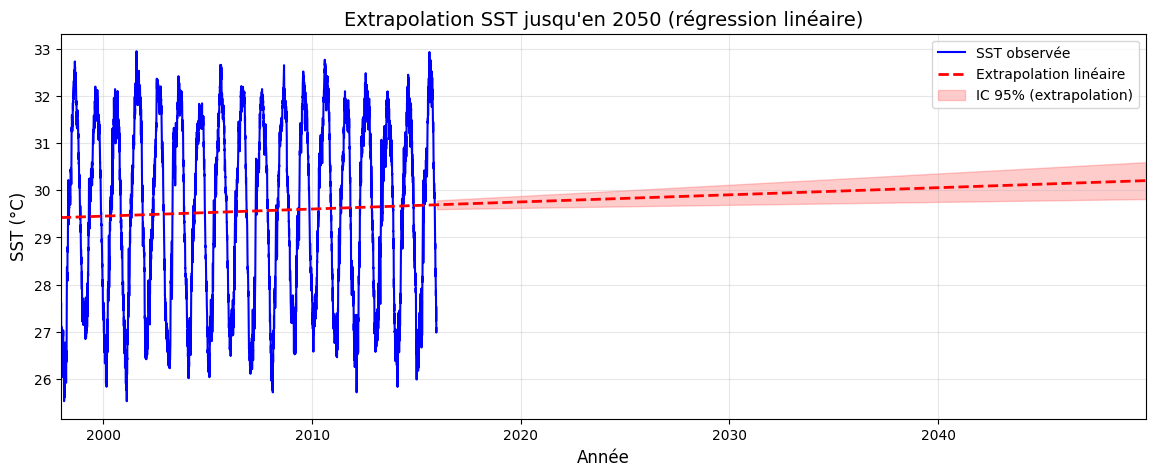

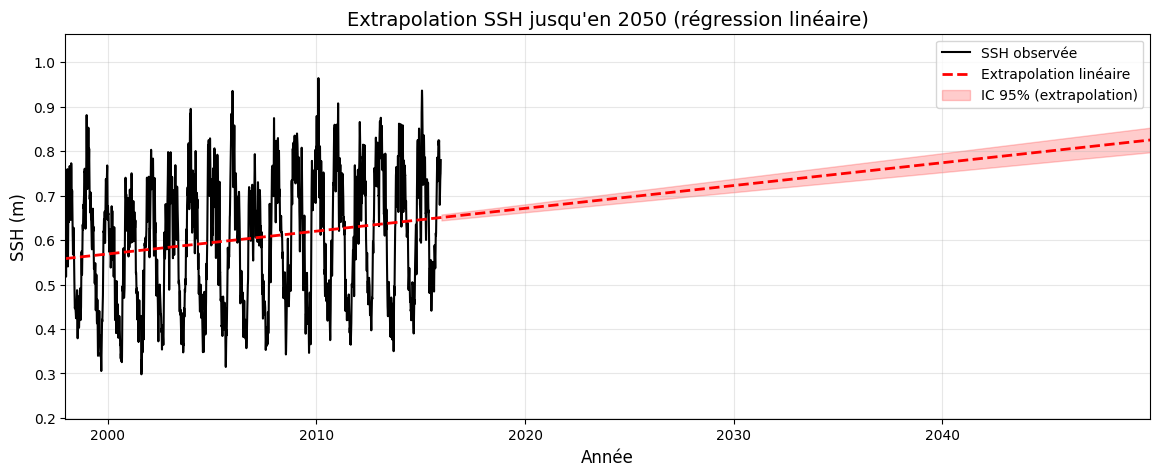

In [ ]:
# --- Extrapolation jusqu'en 2050 pour SST et SSH (avec IC 95%)
import numpy as np
import matplotlib.dates as mdates
import pandas as pd
from scipy import stats
from datetime import datetime

# constante utilisée précédemment pour aligner les dates dans les graphiques
SHIFT = 719177.25

# Utiliser les time_years déjà calculés dans la cellule précédente
# time_years représente les années depuis le début des observations

# Créer une extension temporelle : de la dernière observation jusqu'à 2050
# Calculer combien d'années depuis le début jusqu'à 2050
last_obs_year = time_years.iloc[-1]  # dernière année observée (environ 17 ans depuis 1998)
years_to_2050 = 2050 - 1998  # 52 ans depuis le début

# Créer une grille pour l'extrapolation complète (du début à 2050, pour le tracé complet)
future_time_years_array = np.linspace(0, years_to_2050, int(years_to_2050 * 12))  # résolution mensuelle

# Convertir en numéros de dates matplotlib
first_date_num = df_sst_rs.time.iloc[0]
future_datenums = first_date_num + future_time_years_array * 365.25

# --- Fonction utilitaire pour obtenir prévision et IC 95% à partir d'un fit linéaire
def linear_forecast_with_ci(y, intercept, slope, x_orig, x_pred, alpha=0.05):
    # y : observations originales
    # intercept, slope : paramètres du modèle y = intercept + slope * x
    # x_orig : valeurs x originales (time_years)
    # x_pred : valeurs x pour lesquelles on veut prédire (future_time_years)

    # Convertir en arrays numpy pour la sécurité
    y = np.array(y)
    x_orig = np.array(x_orig)
    x_pred = np.array(x_pred)

    # résidus et erreur standard estimée
    y_fit = intercept + slope * x_orig
    resid = y - y_fit
    s_err = np.sqrt(np.sum(resid**2) / (len(y) - 2))

    x_mean = np.mean(x_orig)
    Sxx = np.sum((x_orig - x_mean)**2)

    # t-critique pour l'IC
    t_val = stats.t.ppf(1 - alpha/2, df=len(y) - 2)

    # prédictions
    y_pred = intercept + slope * x_pred

    # erreur standard de prédiction (intervalle de prédiction pour la moyenne)
    se_pred = s_err * np.sqrt(1.0/len(x_orig) + (x_pred - x_mean)**2 / Sxx)

    ci_upper = y_pred + t_val * se_pred
    ci_lower = y_pred - t_val * se_pred

    return y_pred, ci_lower, ci_upper

# --- SST
sst = df_sst_rs.sst_mean_space.values
sst_pred, sst_ci_lo, sst_ci_up = linear_forecast_with_ci(sst, intercept_sst, slope_sst, time_years, future_time_years_array)

# valeur prévue fin 2050
val_2050_sst = sst_pred[-1]

# --- SSH
ssh = df_sst_rs.ssh_mean_space.values
ssh_pred, ssh_ci_lo, ssh_ci_up = linear_forecast_with_ci(ssh, 0.5584400734029416, 0.005131859826501146, time_years, future_time_years_array)
val_2050_ssh = ssh_pred[-1]

# --- Tracés
import matplotlib.pyplot as plt

# Index pour la partie future (extrapolation)
idx_future = future_time_years_array > last_obs_year

# Pour SST
plt.figure(figsize=(14,5))
# série observée
plt.plot_date(df_sst_rs.time - SHIFT, sst, '-b', label='SST observée', linewidth=1.5)
# extrapolation complète (ligne pointillée)
plt.plot_date(future_datenums - SHIFT, sst_pred, '--r', label='Extrapolation linéaire', linewidth=2)
# intervalle de confiance (seulement pour la partie future)
plt.fill_between(future_datenums[idx_future] - SHIFT, sst_ci_lo[idx_future], sst_ci_up[idx_future],
                 color='red', alpha=0.2, label='IC 95% (extrapolation)')
plt.ylabel('SST (°C)', fontsize=12)
plt.xlabel('Année', fontsize=12)
plt.title('Extrapolation SST jusqu\'en 2050 (régression linéaire)', fontsize=14)
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.xlim([df_sst_rs.time.iloc[0] - SHIFT, future_datenums[-1] - SHIFT])

# Pour SSH
plt.figure(figsize=(14,5))
plt.plot_date(df_sst_rs.time - SHIFT, ssh, '-k', label='SSH observée', linewidth=1.5)
plt.plot_date(future_datenums - SHIFT, ssh_pred, '--r', label='Extrapolation linéaire', linewidth=2)
plt.fill_between(future_datenums[idx_future] - SHIFT, ssh_ci_lo[idx_future], ssh_ci_up[idx_future],
                 color='red', alpha=0.2, label='IC 95% (extrapolation)')
plt.ylabel('SSH (m)', fontsize=12)
plt.xlabel('Année', fontsize=12)
plt.title('Extrapolation SSH jusqu\'en 2050 (régression linéaire)', fontsize=14)
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.xlim([df_sst_rs.time.iloc[0] - SHIFT, future_datenums[-1] - SHIFT])

# Ajuster automatiquement les limites de l'axe Y pour SSH (mieux voir la tendance)
y_min_ssh = np.minimum(ssh.min(), ssh_pred.min())
y_max_ssh = np.maximum(ssh.max(), ssh_pred.max())
margin = (y_max_ssh - y_min_ssh) * 0.15  # marge de 15%
plt.ylim([y_min_ssh - margin, y_max_ssh + margin])

# --- Afficher quelques statistiques utiles
print('='*60)
print('STATISTIQUES D\'EXTRAPOLATION')
print('='*60)
print(f'Période observée : 1998 à ~{1998 + last_obs_year:.0f}')
print(f'Période d\'extrapolation : ~{1998 + last_obs_year:.0f} à 2050')
print()
print('--- SST (Sea Surface Temperature) ---')
print(f'  Valeur observée (dernière)  : {sst[-1]:.3f} °C')
print(f'  Tendance linéaire           : {slope_sst:.4f} °C/an')
print(f'  SST prévue en 2050          : {val_2050_sst:.3f} °C')
print(f'  Augmentation prévue         : +{val_2050_sst - sst[-1]:.3f} °C')
print()
print('--- SSH (Sea Surface Height) ---')
print(f'  Plage observée              : {ssh.min():.4f} à {ssh.max():.4f} m')
print(f'  Valeur observée (dernière)  : {ssh[-1]:.4f} m')
print(f'  Tendance linéaire           : {slope_ssh:.6f} m/an')
print(f'  SSH prévue en 2050          : {val_2050_ssh:.4f} m')
# Calcul correct de la variation (2050 - dernière obs = années_futures * tendance)
annees_futures = years_to_2050 - last_obs_year
variation_attendue = annees_futures * slope_ssh
print(f'  Variation prévue sur {annees_futures:.1f} ans : {variation_attendue:+.4f} m')
print(f'  => Hausse de {variation_attendue*100:.2f} cm')
print('='*60)

# Vérification (à supprimer après debug)
print('\n--- VERIFICATION ---')
print(f'Intercept SSH: {intercept_ssh:.6f}')
print(f'Slope SSH: {slope_ssh:.6f} m/an')
print(f'Années futures (last_obs_year): {last_obs_year:.2f}')
print(f'Années jusqu\'à 2050: {years_to_2050:.2f}')
print(f'SSH calculée manuellement pour 2050: {intercept_ssh + slope_ssh * years_to_2050:.4f} m')
print(f'SSH prévue (fonction): {val_2050_ssh:.4f} m')

In [ ]:
%%bigquery projet3 --project YOUR_GCP_PROJECT
SELECT time, AVG(sst) AS mean_sst, AVG(ssh) AS mean_ssh
FROM bdo2020.bdo2020.1998_2015
WHERE lon>33 AND lon<42 AND lat>14 AND lat<29
GROUP BY time
ORDER BY time

Query is running:   0%|          |

Downloading:   0%|          |

**3.Detection of Particular Years with K-Means (K=2)**

In [ ]:
%%bigquery data_mer_rouge --project YOUR_GCP_PROJECT
SELECT year, month, STDDEV(sst) AS sst_monthly
FROM bdo2020.bdo2020.1998_2015_withtimes
WHERE lon>=32 AND lon<=44 AND lat>=12 AND lat<=30
GROUP BY year, month
ORDER BY year, month

Query is running:   0%|          |

Downloading:   0%|          |

In [ ]:
# Afficher un échantillon des données
data_mer_rouge.head(20)

,year,month,sst_monthly
0,1998,1,1.104560
1,1998,2,1.030004
2,1998,3,0.946064
3,1998,4,1.470743
4,1998,5,0.895303
5,1998,6,0.792647
6,1998,7,0.707514
7,1998,8,0.540612
8,1998,9,0.511676
9,1998,10,0.904236


In [ ]:
# Créer le tableau avec années en lignes et mois en colonnes
from sklearn.cluster import KMeans

# Obtenir les années uniques
years = sorted(data_mer_rouge['year'].unique())

# Créer un tableau vide pour stocker les données
# Colonnes: SST_Jan, SST_Feb, ..., SST_Dec
tableau = []

for year in years:
    data_year = data_mer_rouge[data_mer_rouge['year'] == year]

    # Créer une ligne pour cette année
    row = []

    # Ajouter les 12 mois d'écart-type SST
    for month in range(1, 13):
        data_month = data_year[data_year['month'] == month]
        if len(data_month) > 0:
            row.append(data_month['sst_monthly'].values[0])
        else:
            row.append(nan)  # Si pas de données pour ce mois

    tableau.append(row)

# Convertir en array numpy
tableau = array(tableau)

# Créer les noms de colonnes
column_names = []
for i in range(1, 13):
    column_names.append(f'SST_M{i}')

# Créer un DataFrame pour mieux visualiser
df_tableau = pd.DataFrame(tableau, index=years, columns=column_names)

print("Tableau des écarts-types SST par année (mensuels):")
print(df_tableau)

Tableau des écarts-types SST par année (mensuels):
        SST_M1    SST_M2    SST_M3    SST_M4    SST_M5    SST_M6    SST_M7  \
1998  1.104560  1.030004  0.946064  1.470743  0.895303  0.792647  0.707514   
1999  0.812943  0.653312  0.719337  1.129650  1.036005  0.905309  0.627206   
2000  0.903862  1.038412  1.349040  1.037025  0.977556  0.816711  0.634745   
2001  0.921664  0.983160  0.929606  0.840758  1.025144  0.732299  0.516835   
2002  1.113093  0.919957  0.685404  0.812603  0.770612  0.807576  0.621241   
2003  0.787022  0.823533  1.117674  1.135882  1.315230  0.796681  0.566750   
2004  0.643082  0.686098  0.754568  1.123198  0.929819  0.934946  0.488715   
2005  0.814639  0.742037  0.809578  1.176480  0.911718  0.752545  0.556005   
2006  0.804473  0.767216  0.748465  0.936030  0.932306  0.778836  0.435644   
2007  0.967446  0.857190  0.981062  1.148998  0.938537  0.735948  0.699266   
2008  0.873436  0.734319  0.775902  0.971992  0.847762  0.899506  0.562007   
2009  0.89873

In [ ]:
# Normaliser les données (Z-score) pour K-means
# On retire les NaN s'il y en a
tableau_clean = tableau.copy()
if isnan(tableau_clean).any():
    print("Attention: présence de valeurs manquantes")
    # Remplacer les NaN par la moyenne de la colonne
    for col in range(tableau_clean.shape[1]):
        col_data = tableau_clean[:, col]
        if isnan(col_data).any():
            col_mean = nanmean(col_data)
            tableau_clean[isnan(tableau_clean[:, col]), col] = col_mean

# Normalisation Z-score
tableau_normalized = zscore(tableau_clean, axis=0)

print("Tableau normalisé:")
print(tableau_normalized)

Attention: présence de valeurs manquantes
Tableau normalisé:
[[ 1.36267758e+00  1.68791290e+00  5.83409927e-01  2.84698639e+00
  -7.92412976e-01 -5.90830572e-01  1.84033268e+00  5.48331479e-01
  -4.00541187e-01  1.53675387e+00  2.27383735e-01 -6.66829328e-01]
 [-5.08285525e-01 -7.35497534e-01 -5.97415074e-01  4.86034341e-01
   2.68355382e-01  4.03061301e-01  6.33458256e-01 -8.06136633e-01
   3.18025799e-01  8.81257821e-01  4.01494330e-01  1.50140191e+00]
 [ 7.50317242e-02  1.74200918e+00  2.68216581e+00 -1.55093333e-01
  -1.72298307e-01 -3.78538671e-01  7.46758918e-01  2.57337450e+00
   1.41412589e+00  1.60501438e+00  1.41488383e+00  3.00084268e-01]
 [ 1.89247639e-01  1.38655068e+00  4.97697732e-01 -1.51359917e+00
   1.86472907e-01 -1.12321267e+00 -1.02520079e+00  1.01294044e+00
   1.60866033e+00  1.37118075e+00  1.76948074e+00  2.24780060e-01]
 [ 1.41742201e+00  9.79935995e-01 -7.74140832e-01 -1.70847677e+00
  -1.73247301e+00 -4.59125937e-01  5.43809513e-01 -7.95376929e-01
  -6.681374

In [ ]:
# Appliquer K-means avec k=2
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(tableau_normalized)

# Afficher les résultats
print("\nRésultats du clustering K-means (k=2):")
print("=" * 50)
for i, year in enumerate(years):
    cluster_label = "Particulière" if clusters[i] == 0 else "Régulière"
    print(f"Année {year}: Cluster {clusters[i]} ({cluster_label})")

print("\n" + "=" * 50)
print(f"Cluster 0: {sum(clusters == 0)} années")
print(f"Cluster 1: {sum(clusters == 1)} années")


Résultats du clustering K-means (k=2):
Année 1998: Cluster 0 (Particulière)
Année 1999: Cluster 1 (Régulière)
Année 2000: Cluster 0 (Particulière)
Année 2001: Cluster 0 (Particulière)
Année 2002: Cluster 1 (Régulière)
Année 2003: Cluster 1 (Régulière)
Année 2004: Cluster 1 (Régulière)
Année 2005: Cluster 1 (Régulière)
Année 2006: Cluster 1 (Régulière)
Année 2007: Cluster 1 (Régulière)
Année 2008: Cluster 1 (Régulière)
Année 2009: Cluster 1 (Régulière)
Année 2010: Cluster 1 (Régulière)
Année 2011: Cluster 1 (Régulière)
Année 2012: Cluster 1 (Régulière)
Année 2013: Cluster 1 (Régulière)
Année 2014: Cluster 1 (Régulière)
Année 2015: Cluster 0 (Particulière)
Année 2016: Cluster 1 (Régulière)

Cluster 0: 4 années
Cluster 1: 15 années


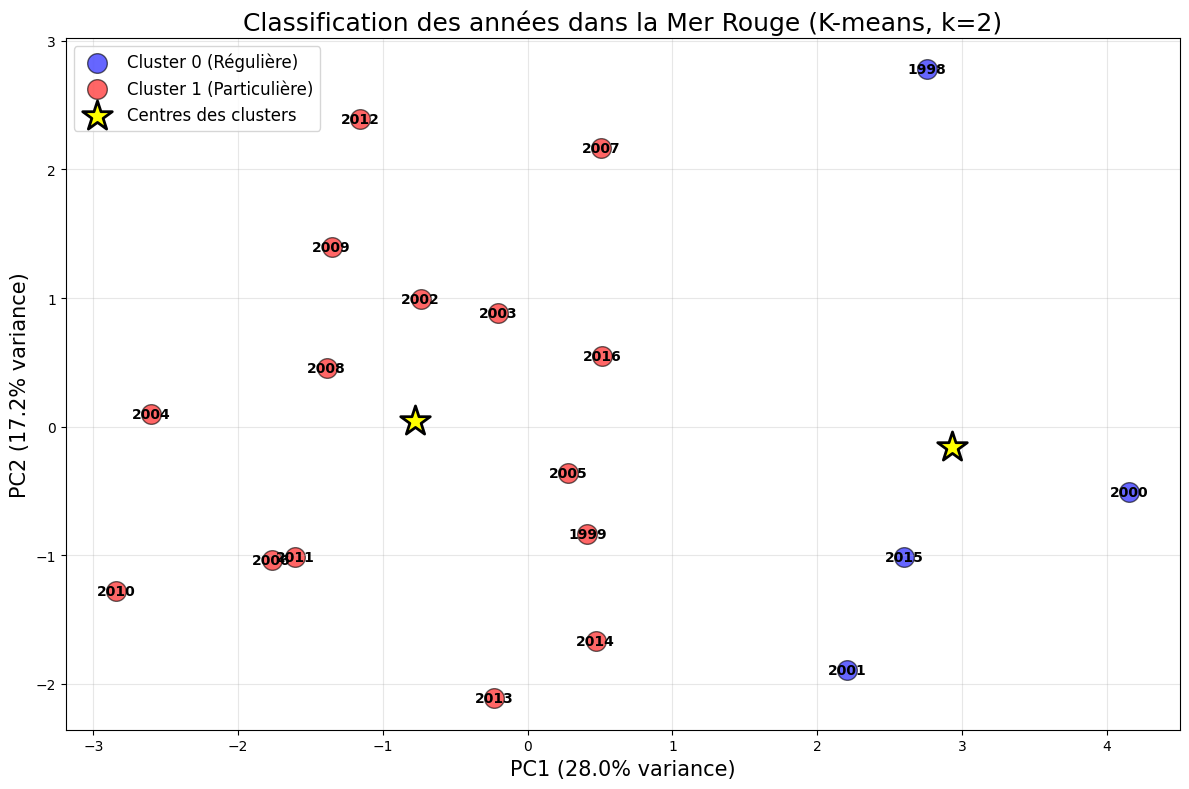

In [ ]:
# Visualisation: projection des années sur les 2 premières composantes principales
from sklearn.decomposition import PCA

# PCA pour visualisation
pca = PCA(n_components=2)
tableau_pca = pca.fit_transform(tableau_normalized)

# Plot
figure(figsize=(12, 8))

# Scatter plot coloré par cluster
scatter(tableau_pca[clusters==0, 0], tableau_pca[clusters==0, 1],
        c='blue', s=200, alpha=0.6, label='Cluster 0 (Particulière)', edgecolors='k')
scatter(tableau_pca[clusters==1, 0], tableau_pca[clusters==1, 1],
        c='red', s=200, alpha=0.6, label='Cluster 1 (Régulière)', edgecolors='k')

# Ajouter les labels des années
for i, year in enumerate(years):
    text(tableau_pca[i, 0], tableau_pca[i, 1], str(year),
         fontsize=10, ha='center', va='center', weight='bold')

# Ajouter les centres des clusters
centers_pca = pca.transform(kmeans.cluster_centers_)
scatter(centers_pca[:, 0], centers_pca[:, 1],
        c='yellow', s=500, marker='*', edgecolors='k', linewidths=2,
        label='Centres des clusters', zorder=10)

xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)', fontsize=15)
ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)', fontsize=15)
title('Classification des années dans la Mer Rouge (K-means, k=2)', fontsize=18)
legend(fontsize=12)
grid(True, alpha=0.3)
tight_layout()

################################################################################"""""

In [ ]:
# Dénormaliser les centroïdes pour les visualiser sur l'échelle originale
# Les centroïdes sont dans l'espace normalisé (Z-score), il faut les ramener à l'échelle originale

# Calculer les moyennes et écarts-types utilisés pour la normalisation
mean_per_col = tableau_clean.mean(axis=0)
std_per_col = tableau_clean.std(axis=0)

# Dénormaliser les centroïdes
centroids_denormalized = kmeans.cluster_centers_ * std_per_col + mean_per_col

print("Centroïdes dénormalisés (échelle originale):")
print("=" * 60)
for i in range(2):
    print(f"\nCentroïde Cluster {i}:")
    print(f"  Écart-type SST moyen annuel: {centroids_denormalized[i, :].mean():.6f}")

Centroïdes dénormalisés (échelle originale):

Centroïde Cluster 0:
  Écart-type SST moyen annuel: 0.915237

Centroïde Cluster 1:
  Écart-type SST moyen annuel: 0.780924


Statistiques des écarts-types SST:
Écart-type SST - Moyenne: 0.809201, Écart-type: 0.068205

Cluster 0 (bleu): 4 années
Cluster 1 (rouge): 15 années

Centroïdes:
Cluster 0 - Écart-type SST: 0.915237
Cluster 1 - Écart-type SST: 0.780924


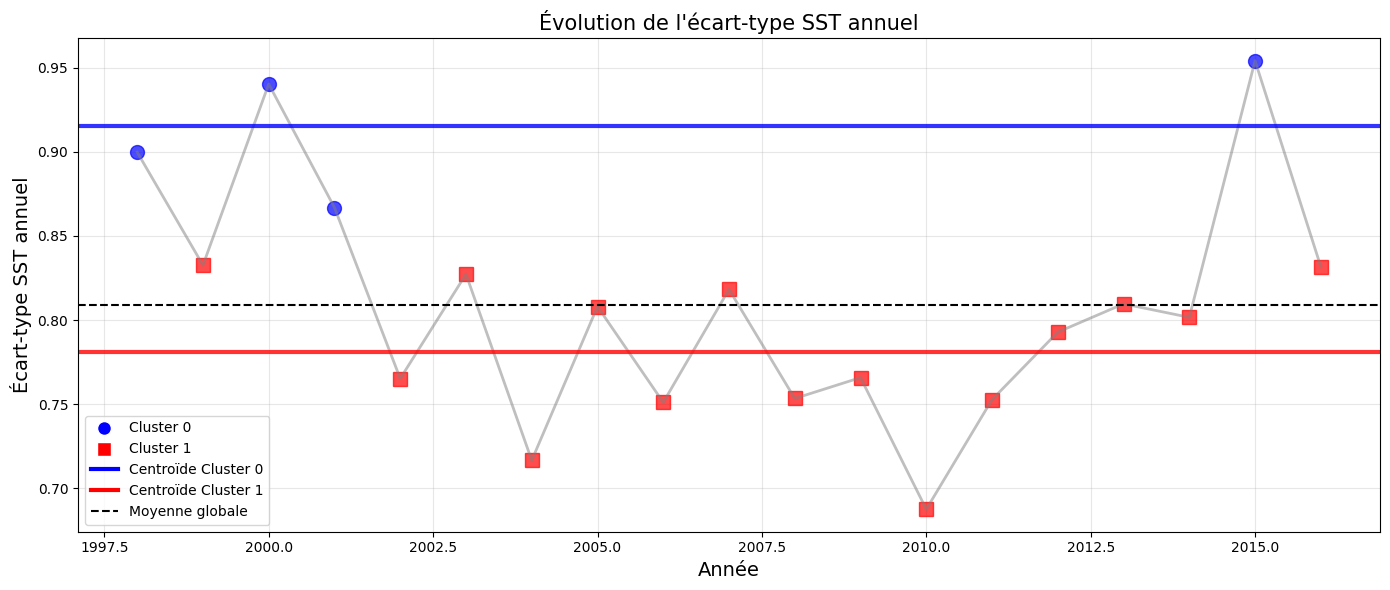

In [ ]:
# Calculer les écarts-types annuels moyens de SST
sst_annual_mean = tableau_clean.mean(axis=1)  # Moyenne des 12 mois pour chaque année

# Calculer les écarts-types annuels des centroïdes
sst_centroid_means = [centroids_denormalized[i, :].mean() for i in range(2)]

# Créer le graphique
figure(figsize=(14, 6))

# Écart-type SST en fonction des années
for i, year in enumerate(years):
    color = 'blue' if clusters[i] == 0 else 'red'
    marker = 'o' if clusters[i] == 0 else 's'
    plot(year, sst_annual_mean[i], marker, markersize=10, color=color, alpha=0.7)

plot(years, sst_annual_mean, '-', linewidth=2, color='gray', alpha=0.5, label='Tendance')

# Ajouter les centroïdes
axhline(y=sst_centroid_means[0], color='blue', linestyle='-', linewidth=3, alpha=0.8, label='Centroïde Cluster 0')
axhline(y=sst_centroid_means[1], color='red', linestyle='-', linewidth=3, alpha=0.8, label='Centroïde Cluster 1')

xlabel('Année', fontsize=14)
ylabel('Écart-type SST annuel', fontsize=14)
title('Évolution de l\'écart-type SST annuel', fontsize=15)
grid(True, alpha=0.3)
axhline(y=sst_annual_mean.mean(), color='black', linestyle='--', linewidth=1.5, label='Moyenne globale')

# Légende pour les clusters
from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=10, label='Cluster 0'),
                   Line2D([0], [0], marker='s', color='w', markerfacecolor='red', markersize=10, label='Cluster 1'),
                   Line2D([0], [0], color='blue', linestyle='-', linewidth=3, label='Centroïde Cluster 0'),
                   Line2D([0], [0], color='red', linestyle='-', linewidth=3, label='Centroïde Cluster 1'),
                   Line2D([0], [0], color='black', linestyle='--', label='Moyenne globale')]
legend(handles=legend_elements, fontsize=10)

tight_layout()

print("Statistiques des écarts-types SST:")
print("=" * 60)
print(f"Écart-type SST - Moyenne: {sst_annual_mean.mean():.6f}, Écart-type: {sst_annual_mean.std():.6f}")
print(f"\nCluster 0 (bleu): {sum(clusters==0)} années")
print(f"Cluster 1 (rouge): {sum(clusters==1)} années")
print(f"\nCentroïdes:")
print(f"Cluster 0 - Écart-type SST: {sst_centroid_means[0]:.6f}")
print(f"Cluster 1 - Écart-type SST: {sst_centroid_means[1]:.6f}")


Séries temporelles mensuelles des écarts-types SST
Nombre total de points: 228 (18 années × 12 mois)
Période: 1998-2016


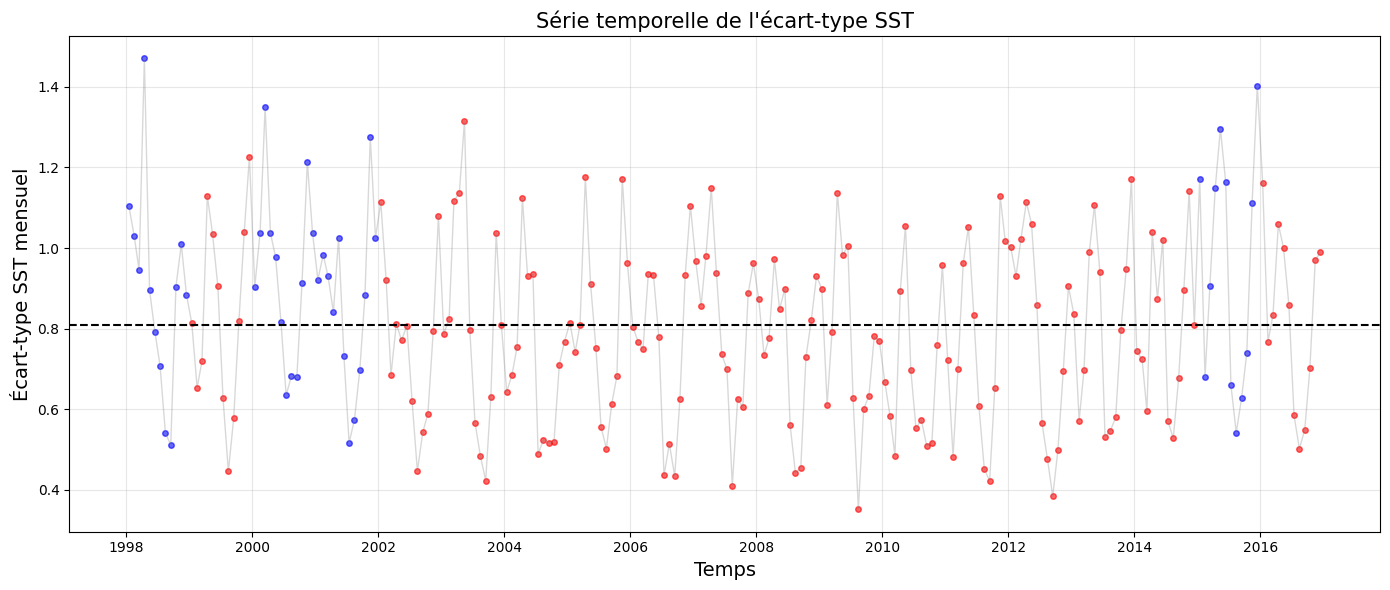

In [ ]:
# Série temporelle complète (toutes les valeurs mensuelles d'écart-type)
figure(figsize=(14, 6))

# Créer un vecteur temps pour les mois
import datetime
time_months = []
for year in years:
    for month in range(1, 13):
        time_months.append(datetime.datetime(year, month, 15))

# Aplatir les données mensuelles d'écart-type
sst_monthly_series = tableau_clean.flatten()

# Créer un vecteur de couleurs basé sur les clusters
colors_series = []
for i, year in enumerate(years):
    color = 'blue' if clusters[i] == 0 else 'red'
    colors_series.extend([color] * 12)

# Écart-type SST mensuel
for i in range(len(time_months)):
    plot_date([time_months[i]], [sst_monthly_series[i]], 'o',
              color=colors_series[i], markersize=4, alpha=0.6)
plot_date(time_months, sst_monthly_series, '-', color='gray', linewidth=1, alpha=0.3)
xlabel('Temps', fontsize=14)
ylabel('Écart-type SST mensuel', fontsize=14)
title('Série temporelle de l\'écart-type SST', fontsize=15)
grid(True, alpha=0.3)
axhline(y=sst_monthly_series.mean(), color='black', linestyle='--', linewidth=1.5)

tight_layout()

print("\nSéries temporelles mensuelles des écarts-types SST")
print(f"Nombre total de points: {len(time_months)} (18 années × 12 mois)")
print(f"Période: {time_months[0].year}-{time_months[-1].year}")

Années appartenant à chaque cluster:
Cluster 0: [np.int64(1998), np.int64(2000), np.int64(2001), np.int64(2015)]
Cluster 1: [np.int64(1999), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2016)]

Les étoiles (★) représentent les centroïdes:
- Centroïde = prototype moyen de chaque cluster
- Montre le cycle saisonnier 'typique' de l'écart-type SST pour chaque groupe d'années


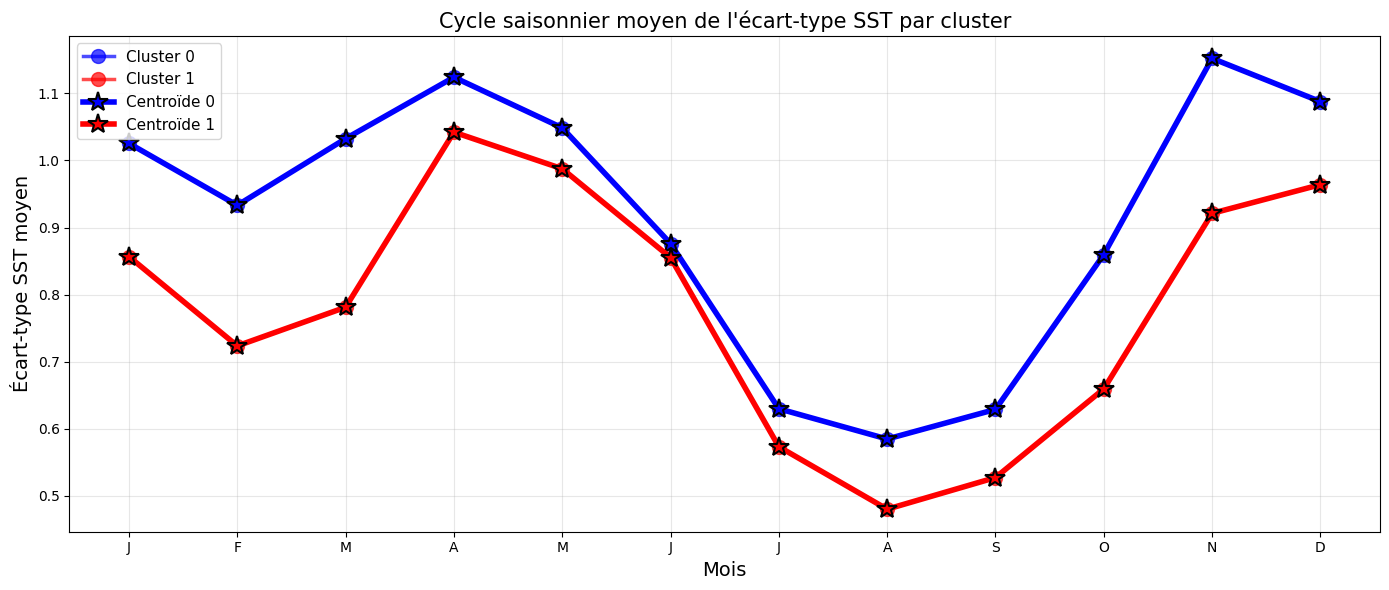

In [ ]:
# Comparaison des cycles saisonniers des écarts-types moyens pour les deux clusters
figure(figsize=(14, 6))

# Calculer les cycles saisonniers des écarts-types moyens pour chaque cluster
for cluster_id in range(2):
    cluster_indices = where(clusters == cluster_id)[0]
    cluster_data = tableau_clean[cluster_indices, :]

    # Moyennes mensuelles des écarts-types
    sst_monthly_mean = cluster_data.mean(axis=0)

    color = 'blue' if cluster_id == 0 else 'red'

    # Écart-type SST
    plot(range(1, 13), sst_monthly_mean, 'o-', linewidth=2.5, markersize=10,
         label=f'Cluster {cluster_id}', color=color, alpha=0.7)

# Ajouter les centroïdes (cycle saisonnier du prototype de chaque cluster)
for cluster_id in range(2):
    color = 'blue' if cluster_id == 0 else 'red'

    # Écart-type SST - tracer le centroïde
    plot(range(1, 13), centroids_denormalized[cluster_id, :], '*-',
         linewidth=4, markersize=15, color=color, alpha=1.0,
         label=f'Centroïde {cluster_id}', markeredgecolor='black', markeredgewidth=1.5)

xlabel('Mois', fontsize=14)
ylabel('Écart-type SST moyen', fontsize=14)
title('Cycle saisonnier moyen de l\'écart-type SST par cluster', fontsize=15)
legend(fontsize=11)
grid(True, alpha=0.3)
xticks(range(1, 13), ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])

tight_layout()

# Afficher les années de chaque cluster
print("Années appartenant à chaque cluster:")
print("=" * 60)
for cluster_id in range(2):
    cluster_indices = where(clusters == cluster_id)[0]
    cluster_years = [years[i] for i in cluster_indices]
    print(f"Cluster {cluster_id}: {cluster_years}")

print("\nLes étoiles (★) représentent les centroïdes:")
print("- Centroïde = prototype moyen de chaque cluster")
print("- Montre le cycle saisonnier 'typique' de l'écart-type SST pour chaque groupe d'années")

Années appartenant à chaque cluster:
Cluster 0: [np.int64(1998), np.int64(2000), np.int64(2001), np.int64(2015)]
Cluster 1: [np.int64(1999), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2016)]

Légende du graphique:
- Lignes fines semi-transparentes: cycles saisonniers individuels des écarts-types SST de chaque année
- Étoiles (★) épaisses: centroïdes = prototype moyen de chaque cluster
- Bleu: Cluster 0, Rouge: Cluster 1
- Permet de visualiser la dispersion des écarts-types des années autour de leur centroïde


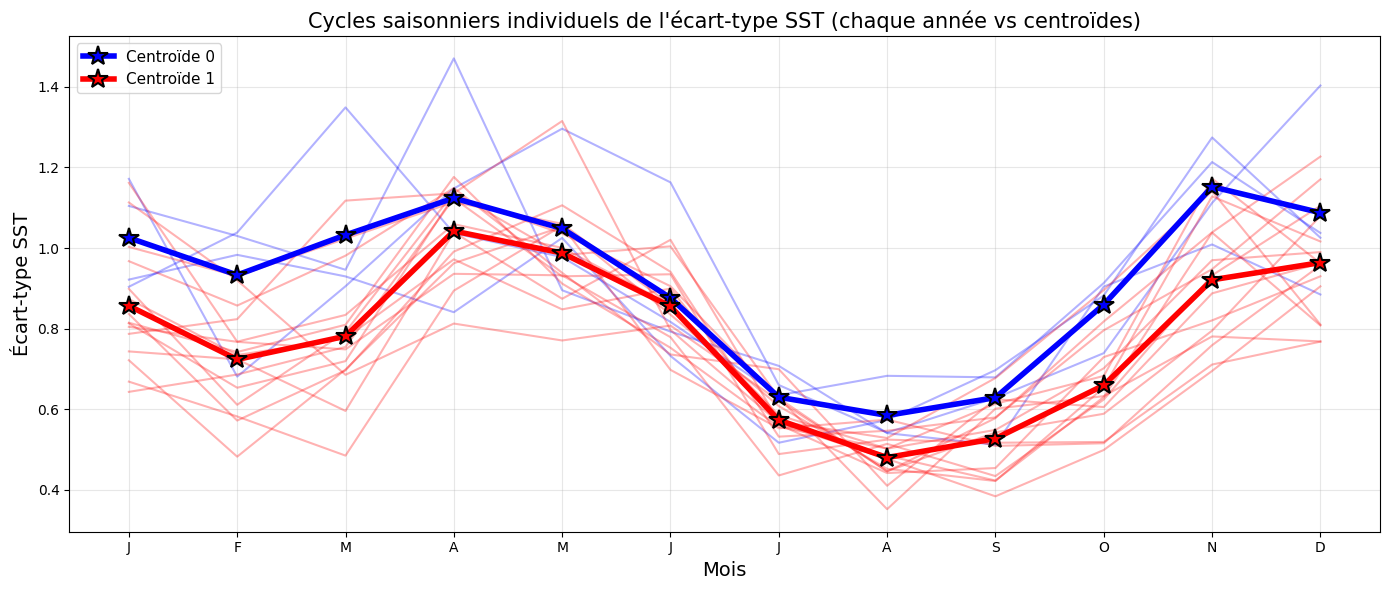

In [ ]:
# Comparaison des cycles saisonniers individuels des écarts-types (chaque année) avec les centroïdes
figure(figsize=(14, 6))

# Tracer chaque année individuellement par cluster
for cluster_id in range(2):
    cluster_indices = where(clusters == cluster_id)[0]
    cluster_data = tableau_clean[cluster_indices, :]

    color = 'blue' if cluster_id == 0 else 'red'

    # Tracer chaque année du cluster
    for idx in cluster_indices:
        year_data = tableau_clean[idx, :]
        sst_monthly = year_data

        # Écart-type SST - tracer chaque année avec transparence
        plot(range(1, 13), sst_monthly, '-', linewidth=1.5,
             color=color, alpha=0.3)

# Ajouter les centroïdes par-dessus (cycle saisonnier du prototype de chaque cluster)
for cluster_id in range(2):
    color = 'blue' if cluster_id == 0 else 'red'

    # Écart-type SST - tracer le centroïde
    plot(range(1, 13), centroids_denormalized[cluster_id, :], '*-',
         linewidth=4, markersize=15, color=color, alpha=1.0,
         label=f'Centroïde {cluster_id}', markeredgecolor='black', markeredgewidth=1.5, zorder=10)

xlabel('Mois', fontsize=14)
ylabel('Écart-type SST', fontsize=14)
title('Cycles saisonniers individuels de l\'écart-type SST (chaque année vs centroïdes)', fontsize=15)
legend(fontsize=11, loc='best')
grid(True, alpha=0.3)
xticks(range(1, 13), ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])

tight_layout()

# Afficher les années de chaque cluster
print("Années appartenant à chaque cluster:")
print("=" * 60)
for cluster_id in range(2):
    cluster_indices = where(clusters == cluster_id)[0]
    cluster_years = [years[i] for i in cluster_indices]
    print(f"Cluster {cluster_id}: {cluster_years}")

print("\nLégende du graphique:")
print("- Lignes fines semi-transparentes: cycles saisonniers individuels des écarts-types SST de chaque année")
print("- Étoiles (★) épaisses: centroïdes = prototype moyen de chaque cluster")
print("- Bleu: Cluster 0, Rouge: Cluster 1")
print("- Permet de visualiser la dispersion des écarts-types des années autour de leur centroïde")

################################################################################

In [ ]:
%%bigquery data_spatial --project YOUR_GCP_PROJECT
SELECT lon, lat, month, STDDEV(sst) AS sst_monthly
FROM bdo2020.bdo2020.1998_2015_withtimes
WHERE lon>=32 AND lon<=44 AND lat>=12 AND lat<=30
GROUP BY lon, lat, month
ORDER BY lon, lat, month

Query is running:   0%|          |

Downloading:   0%|          |

In [ ]:
# Créer le tableau spatial (chaque pixel a 12 features: 12 mois SST)
locations = data_spatial[['lon', 'lat']].drop_duplicates().reset_index(drop=True)
print(f"Nombre de pixels spatiaux: {len(locations)}")

tableau_spatial = []
valid_locations = []

for idx, row in locations.iterrows():
    lon_val = row['lon']
    lat_val = row['lat']

    # Extraire les données pour ce pixel
    pixel_data = data_spatial[(data_spatial['lon'] == lon_val) & (data_spatial['lat'] == lat_val)]

    if len(pixel_data) == 12:  # S'assurer qu'on a les 12 mois
        pixel_row = []

        # Ajouter les 12 mois de SST
        for month in range(1, 13):
            month_data = pixel_data[pixel_data['month'] == month]
            if len(month_data) > 0:
                pixel_row.append(month_data['sst_monthly'].values[0])
            else:
                pixel_row.append(nan)

        # Vérifier s'il n'y a pas trop de NaN
        if sum(isnan(pixel_row)) < 5:
            tableau_spatial.append(pixel_row)
            valid_locations.append([lon_val, lat_val])

tableau_spatial = array(tableau_spatial)
valid_locations = array(valid_locations)

print(f"Nombre de pixels valides: {len(valid_locations)}")

Nombre de pixels spatiaux: 87
Nombre de pixels valides: 87


In [ ]:
# Nettoyer et normaliser les données spatiales
tableau_spatial_clean = tableau_spatial.copy()

# Remplacer les NaN par la moyenne de la colonne
for col in range(tableau_spatial_clean.shape[1]):
    col_data = tableau_spatial_clean[:, col]
    if isnan(col_data).any():
        col_mean = nanmean(col_data)
        tableau_spatial_clean[isnan(tableau_spatial_clean[:, col]), col] = col_mean

# Normalisation avec les mêmes paramètres que pour les années (important!)
# On utilise le même transformateur PCA que pour les années
tableau_spatial_normalized = zscore(tableau_spatial_clean, axis=0)

print("Données spatiales normalisées, shape:", tableau_spatial_normalized.shape)

Données spatiales normalisées, shape: (87, 12)


In [ ]:
# Projeter les données spatiales sur la première composante principale
# Utiliser le même PCA que celui calculé pour les années
tableau_spatial_pca = pca.transform(tableau_spatial_normalized)

# Extraire la première composante (PC1)
pc1_spatial = tableau_spatial_pca[:, 0]

print(f"PC1 spatial - min: {pc1_spatial.min():.3f}, max: {pc1_spatial.max():.3f}, mean: {pc1_spatial.mean():.3f}")

PC1 spatial - min: -3.169, max: 4.946, mean: 0.000



Interprétation:
- PC1 explique 28.0% de la variance totale
- Les valeurs positives (rouge) et négatives (bleu) montrent les régions avec des patterns opposés
- Cette carte révèle les gradients spatiaux dominants dans la Mer Rouge


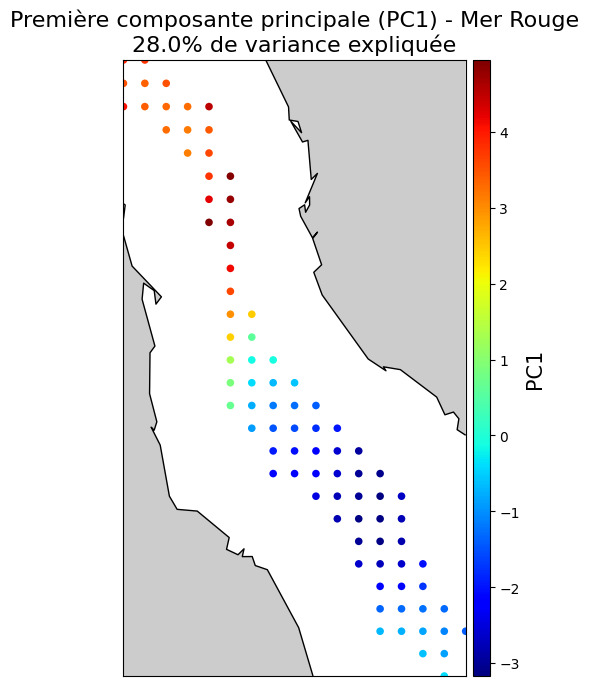

In [ ]:
# Visualisation spatiale de PC1
figure(figsize=(12, 8))

plot_im(valid_locations[:, 0], valid_locations[:, 1], pc1_spatial, 30, 'PC1')
title(f'Première composante principale (PC1) - Mer Rouge\n{pca.explained_variance_ratio_[0]*100:.1f}% de variance expliquée', size=16)

# Ajouter une explication
print("\nInterprétation:")
print(f"- PC1 explique {pca.explained_variance_ratio_[0]*100:.1f}% de la variance totale")
print("- Les valeurs positives (rouge) et négatives (bleu) montrent les régions avec des patterns opposés")
print("- Cette carte révèle les gradients spatiaux dominants dans la Mer Rouge")

In [ ]:
# Extraire la deuxième composante principale (PC2)
pc2_spatial = tableau_spatial_pca[:, 1]

print(f"PC2 spatial - min: {pc2_spatial.min():.3f}, max: {pc2_spatial.max():.3f}, mean: {pc2_spatial.mean():.3f}")

PC2 spatial - min: -2.564, max: 1.223, mean: 0.000



Interprétation:
- PC2 explique 17.2% de la variance totale
- PC2 capture les patterns secondaires non expliqués par PC1
- Cette carte révèle une structure spatiale complémentaire dans la Mer Rouge


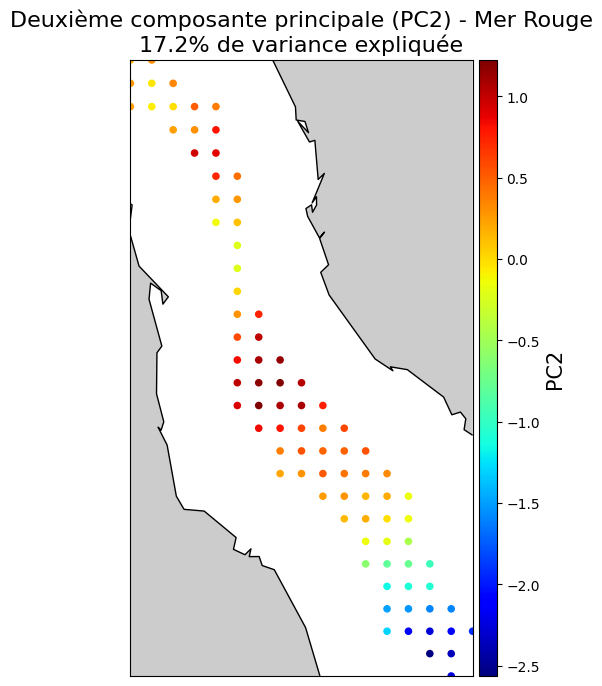

In [ ]:
# Visualisation spatiale de PC2
figure(figsize=(12, 8))

plot_im(valid_locations[:, 0], valid_locations[:, 1], pc2_spatial, 30, 'PC2')
title(f'Deuxième composante principale (PC2) - Mer Rouge\n{pca.explained_variance_ratio_[1]*100:.1f}% de variance expliquée', size=16)

# Ajouter une explication
print("\nInterprétation:")
print(f"- PC2 explique {pca.explained_variance_ratio_[1]*100:.1f}% de la variance totale")
print("- PC2 capture les patterns secondaires non expliqués par PC1")
print("- Cette carte révèle une structure spatiale complémentaire dans la Mer Rouge")

**4.Spatial Clustering :** In This Part, we will make a 3 class spatial clustering in order to see the differences between different regions (here north , middle , south)

In [ ]:
%%bigquery data_spatial --project YOUR_GCP_PROJECT
SELECT lon, lat, month, AVG(sst) AS sst_monthly, AVG(ssh) AS ssh_monthly
FROM bdo2020.bdo2020.1998_2015_withtimes
WHERE lon>=32 AND lon<=44 AND lat>=12 AND lat<=30
GROUP BY lon, lat, month
ORDER BY lon, lat, month

Query is running:   0%|          |

Downloading:   0%|          |

In [ ]:
# Créer le tableau spatial (chaque pixel a 24 features: 12 mois SST + 12 mois SSH)
locations = data_spatial[['lon', 'lat']].drop_duplicates().reset_index(drop=True)
print(f"Nombre de pixels spatiaux: {len(locations)}")

tableau_spatial = []
valid_locations = []

for idx, row in locations.iterrows():
    lon_val = row['lon']
    lat_val = row['lat']

    # Extraire les données pour ce pixel
    pixel_data = data_spatial[(data_spatial['lon'] == lon_val) & (data_spatial['lat'] == lat_val)]

    if len(pixel_data) == 12:  # S'assurer qu'on a les 12 mois
        pixel_row = []

        # Ajouter les 12 mois de SST
        for month in range(1, 13):
            month_data = pixel_data[pixel_data['month'] == month]
            if len(month_data) > 0:
                pixel_row.append(month_data['sst_monthly'].values[0])
            else:
                pixel_row.append(nan)

        # Ajouter les 12 mois de SSH
        for month in range(1, 13):
            month_data = pixel_data[pixel_data['month'] == month]
            if len(month_data) > 0:
                pixel_row.append(month_data['ssh_monthly'].values[0])
            else:
                pixel_row.append(nan)

        # Vérifier s'il n'y a pas trop de NaN
        if sum(isnan(pixel_row)) < 5:
            tableau_spatial.append(pixel_row)
            valid_locations.append([lon_val, lat_val])

tableau_spatial = array(tableau_spatial)
valid_locations = array(valid_locations)

print(f"Nombre de pixels valides: {len(valid_locations)}")

Nombre de pixels spatiaux: 87
Nombre de pixels valides: 87


In [ ]:
data_spatial

,lon,lat,month,sst_monthly,ssh_monthly
0,36.875,23.125,1,25.744355,0.597560
1,36.875,23.125,2,25.399902,0.620855
2,36.875,23.125,3,25.613978,0.565638
3,36.875,23.125,4,26.441667,0.554564
4,36.875,23.125,5,28.035215,0.513540
...,...,...,...,...,...
1039,40.875,17.375,8,32.279301,0.477952
1040,40.875,17.375,9,32.514444,0.492990
1041,40.875,17.375,10,32.253763,0.622073
1042,40.875,17.375,11,30.826111,0.742734


In [ ]:
# Nettoyer et normaliser les données spatiales
tableau_spatial_clean = tableau_spatial.copy()

# Remplacer les NaN par la moyenne de la colonne
for col in range(tableau_spatial_clean.shape[1]):
    col_data = tableau_spatial_clean[:, col]
    if isnan(col_data).any():
        col_mean = nanmean(col_data)
        tableau_spatial_clean[isnan(tableau_spatial_clean[:, col]), col] = col_mean

# Normalisation avec les mêmes paramètres que pour les années (important!)
# On utilise le même transformateur PCA que pour les années
tableau_spatial_normalized = zscore(tableau_spatial_clean, axis=0)

print("Données spatiales normalisées, shape:", tableau_spatial_normalized.shape)

Données spatiales normalisées, shape: (87, 24)


In [ ]:
# Projeter les données spatiales sur la première composante principale
from sklearn.decomposition import PCA
pca_spatial = PCA(n_components=2) # Initialize a new PCA for the 24 features
tableau_spatial_pca = pca_spatial.fit_transform(tableau_spatial_normalized)

# Extraire la première composante (PC1)
pc1_spatial = tableau_spatial_pca[:, 0]

print(f"PC1 spatial - min: {pc1_spatial.min():.3f}, max: {pc1_spatial.max():.3f}, mean: {pc1_spatial.mean():.3f}")

PC1 spatial - min: -8.006, max: 4.239, mean: -0.000



Interprétation:
- PC1 explique 17.3% de la variance totale
- Les valeurs positives (rouge) et négatives (bleu) montrent les régions avec des patterns opposés
- Cette carte révèle les gradients spatiaux dominants dans la Mer Rouge


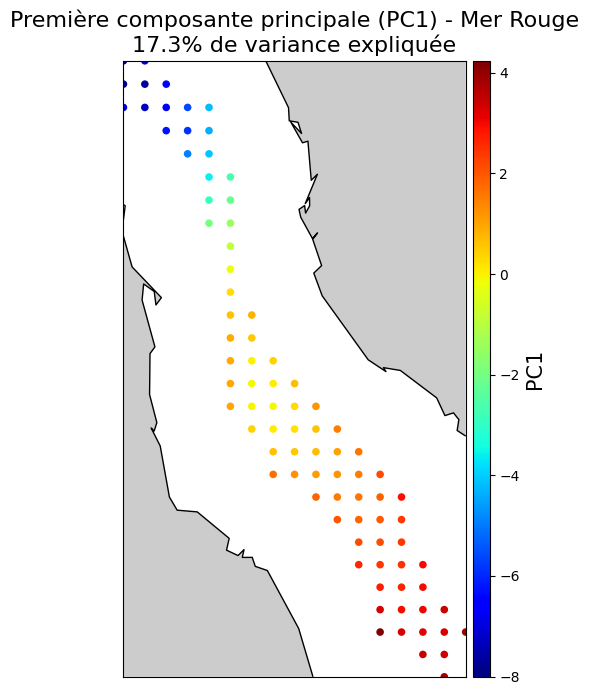

In [ ]:
# Visualisation spatiale de PC1
figure(figsize=(12, 8))

plot_im(valid_locations[:, 0], valid_locations[:, 1], pc1_spatial, 30, 'PC1')
title(f'Première composante principale (PC1) - Mer Rouge\n{pca.explained_variance_ratio_[0]*100:.1f}% de variance expliquée', size=16)

# Ajouter une explication
print("\nInterprétation:")
print(f"- PC1 explique {pca.explained_variance_ratio_[0]*100:.1f}% de la variance totale")
print("- Les valeurs positives (rouge) et négatives (bleu) montrent les régions avec des patterns opposés")
print("- Cette carte révèle les gradients spatiaux dominants dans la Mer Rouge")

In [ ]:
# Extraire la deuxième composante principale (PC2)
pc2_spatial = tableau_spatial_pca[:, 1]

print(f"PC2 spatial - min: {pc2_spatial.min():.3f}, max: {pc2_spatial.max():.3f}, mean: {pc2_spatial.mean():.3f}")

PC2 spatial - min: -1.032, max: 1.518, mean: 0.000



Interprétation:
- PC2 explique 15.4% de la variance totale
- PC2 capture les patterns secondaires non expliqués par PC1
- Cette carte révèle une structure spatiale complémentaire dans la Mer Rouge


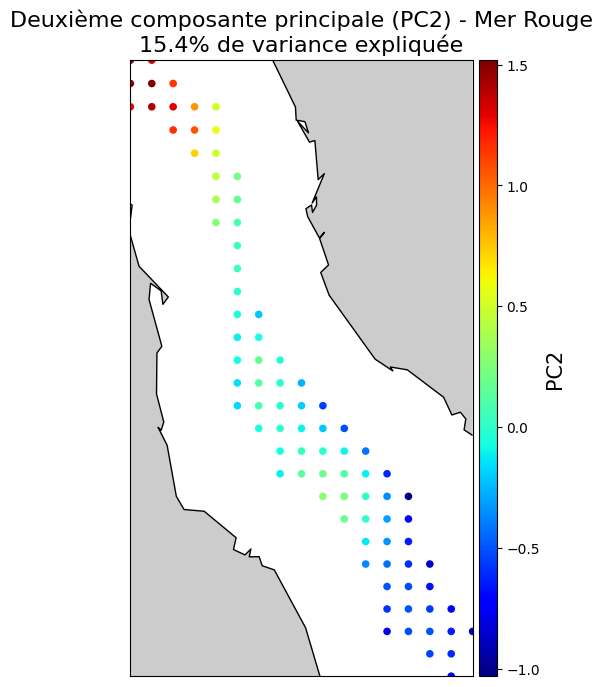

In [ ]:
# Visualisation spatiale de PC2
figure(figsize=(12, 8))

plot_im(valid_locations[:, 0], valid_locations[:, 1], pc2_spatial, 30, 'PC2')
title(f'Deuxième composante principale (PC2) - Mer Rouge\n{pca.explained_variance_ratio_[1]*100:.1f}% de variance expliquée', size=16)

# Ajouter une explication
print("\nInterprétation:")
print(f"- PC2 explique {pca.explained_variance_ratio_[1]*100:.1f}% de la variance totale")
print("- PC2 capture les patterns secondaires non expliqués par PC1")
print("- Cette carte révèle une structure spatiale complémentaire dans la Mer Rouge")

In [ ]:
# Appliquer K-means spatial avec k=3 (par exemple: nord, centre, sud)
n_clusters_spatial = 3
kmeans_spatial = KMeans(n_clusters=n_clusters_spatial, random_state=42, n_init=10)
clusters_spatial = kmeans_spatial.fit_predict(tableau_spatial_normalized)

print(f"Clustering spatial avec {n_clusters_spatial} clusters")
print("=" * 50)
for i in range(n_clusters_spatial):
    n_pixels = sum(clusters_spatial == i)
    print(f"Cluster {i}: {n_pixels} pixels")

# Afficher la répartition spatiale
print("\nRépartition géographique:")
for i in range(n_clusters_spatial):
    lons_cluster = valid_locations[clusters_spatial == i, 0]
    lats_cluster = valid_locations[clusters_spatial == i, 1]
    print(f"Cluster {i} - Longitude: [{lons_cluster.min():.1f}, {lons_cluster.max():.1f}], Latitude: [{lats_cluster.min():.1f}, {lats_cluster.max():.1f}]")

Clustering spatial avec 3 clusters
Cluster 0: 51 pixels
Cluster 1: 20 pixels
Cluster 2: 16 pixels

Répartition géographique:
Cluster 0 - Longitude: [38.4, 40.9], Latitude: [16.9, 20.1]
Cluster 1 - Longitude: [37.9, 38.6], Latitude: [19.9, 22.4]
Cluster 2 - Longitude: [36.9, 37.9], Latitude: [22.4, 23.6]



Interprétation:
- 3 régions océanographiques distinctes identifiées
- Chaque couleur représente une région avec un comportement SST/SSH similaire
- Permet d'identifier des zones homogènes (nord, centre, sud, etc.)


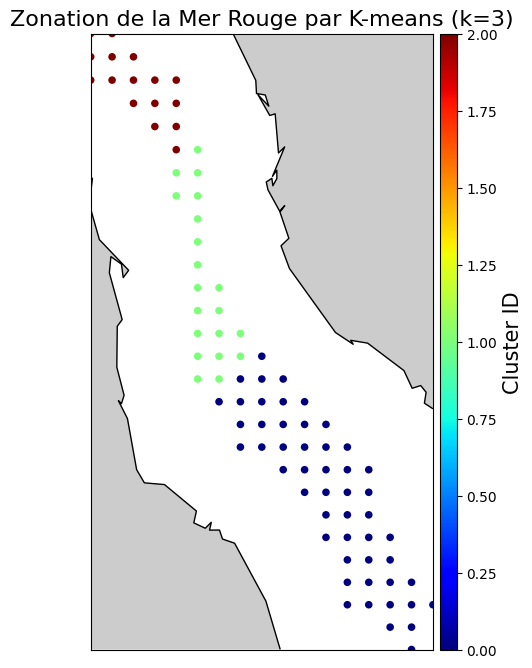

In [ ]:
# Visualisation des clusters spatiaux
figure(figsize=(12, 8))

plot_im(valid_locations[:, 0], valid_locations[:, 1], clusters_spatial, 30, 'Cluster ID')
title(f'Zonation de la Mer Rouge par K-means (k={n_clusters_spatial})', size=16)

print("\nInterprétation:")
print(f"- {n_clusters_spatial} régions océanographiques distinctes identifiées")
print("- Chaque couleur représente une région avec un comportement SST/SSH similaire")
print("- Permet d'identifier des zones homogènes (nord, centre, sud, etc.)")

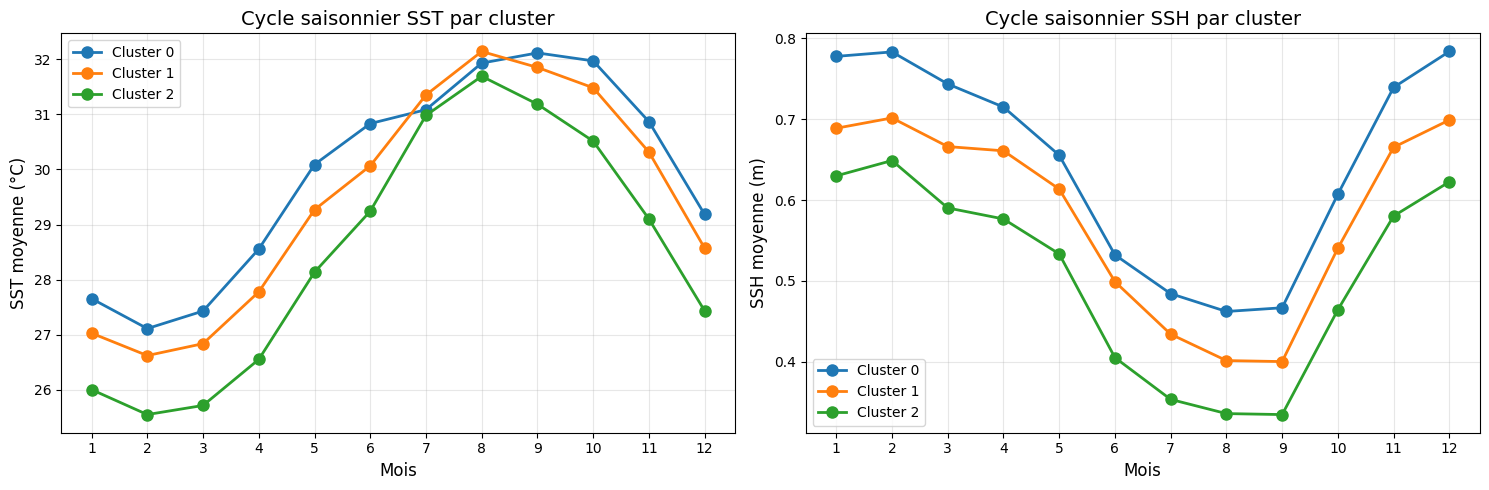

In [ ]:
# Analyser les caractéristiques de chaque cluster
figure(figsize=(15, 5))

for i in range(n_clusters_spatial):
    # Extraire les données du cluster
    cluster_data = tableau_spatial_clean[clusters_spatial == i, :]

    # Calculer les moyennes mensuelles
    sst_monthly_mean = cluster_data[:, :12].mean(axis=0)
    ssh_monthly_mean = cluster_data[:, 12:].mean(axis=0)

    # Subplot pour SST
    subplot(1, 2, 1)
    plot(range(1, 13), sst_monthly_mean, 'o-', linewidth=2, markersize=8, label=f'Cluster {i}')

    # Subplot pour SSH
    subplot(1, 2, 2)
    plot(range(1, 13), ssh_monthly_mean, 'o-', linewidth=2, markersize=8, label=f'Cluster {i}')

# Finaliser SST plot
subplot(1, 2, 1)
xlabel('Mois', fontsize=12)
ylabel('SST moyenne (°C)', fontsize=12)
title('Cycle saisonnier SST par cluster', fontsize=14)
legend()
grid(True, alpha=0.3)
xticks(range(1, 13))

# Finaliser SSH plot
subplot(1, 2, 2)
xlabel('Mois', fontsize=12)
ylabel('SSH moyenne (m)', fontsize=12)
title('Cycle saisonnier SSH par cluster', fontsize=14)
legend()
grid(True, alpha=0.3)
xticks(range(1, 13))

tight_layout()